# Introduction to the Dimensions API

Dimensions brings together information about research outputs and activities including publications, grants, patents, researchers, and organizations.

In this introductory workbook, we will keep the inquiry simple. We will:

- connect to the Dimensions API
- run a small publication query
- inspect the returned data
- search publications for a research topic
- select a few useful fields
- create a pandas DataFrame
- make a simple visualization
- modify the query to investigate a topic of your own

The goal is to learn the basic Dimensions query workflow before moving to more elaborate questions linking research, funding, and patents.


## 1. Setup

This notebook uses the `dimcli` Python package to communicate with the Dimensions API. `dimcli` provides a Python interface for authenticating with Dimensions and submitting queries using the **Dimensions Search Language (DSL)**.

Access to the Dimensions API requires an API key and appropriate Dimensions access through your institution.

For this workshop, store your API key in a `config.yml` file in the same directory as the notebook:

```yaml
dimensions_api_key: YOUR_DIMENSIONS_API_KEY
```

The notebook will read the API key from this file rather than storing it directly in the notebook.

Do not commit `config.yml` or other files containing API keys to a public repository.


In [1]:
import yaml
import pandas as pd
import dimcli

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["dimensions_api_key"]

dimcli.login(
    key=API_KEY,
    endpoint="https://app.dimensions.ai"
)

dsl = dimcli.Dsl()


Dimcli - Dimensions API Client (v1.8)
Connected to: <https://app.dimensions.ai/api/dsl> - DSL v2.16
Method: manual login


## 3. Run a Small Publication Query

We will begin with a very small query so that the structure is easy to inspect.

This asks Dimensions for a few publications and returns selected fields.


In [2]:
query = '''
search publications
return publications[
    id
    + title
    + year
    + type
    + doi
]
limit 5
'''

result = dsl.query(query)


Returned Publications: 5 (total = 171062193)
Time: 0.97s


### Look at the result

Before doing any analysis, inspect what Dimensions returned.


In [3]:
result


<dimcli.DslDataset object #140205319358640. Records: 5/171062193>

The `dimcli` result object can expose the returned publication records directly.


In [4]:
result.publications


[{'doi': '10.1007/s11481-010-9255-2',
  'id': 'pub.1208207710',
  'title': 'Education Mission for Neuroimmune Pharmacology',
  'type': 'article',
  'year': 2011},
 {'doi': '10.12688/f1000research.180230.1',
  'id': 'pub.1208207709',
  'title': 'Breathing exercises as adjunct therapy in adult asthma: a systematic review',
  'type': 'article',
  'year': 2026},
 {'id': 'pub.1208207708',
  'title': 'Bupivacaine instillation after herniorrhaphy.',
  'type': 'article',
  'year': 1992},
 {'doi': '10.31053/1853.0605.v83.n3.49923',
  'id': 'pub.1208207707',
  'title': 'Subspinal osteotomy for mesiodens extraction. A technical note.',
  'type': 'article',
  'year': 2026},
 {'doi': '10.31053/1853.0605.v83.n3.50187',
  'id': 'pub.1208207706',
  'title': '[How to design an interobserver reliability study for categorical variables: a literature review]',
  'type': 'article',
  'year': 2026}]

Look at the first publication record.


In [5]:
result.publications[0]


{'doi': '10.1007/s11481-010-9255-2',
 'id': 'pub.1208207710',
 'title': 'Education Mission for Neuroimmune Pharmacology',
 'type': 'article',
 'year': 2011}

This is the same general lesson we saw with OpenAlex and USPTO: an information system may contain a great deal of data, but we choose which fields to request and investigate.


## 4. Search Publications by Research Topic

Now let's ask a more recognizable research question.

The search term is deliberately stored in a variable so that it is easy to replace later.


In [6]:
SEARCH_TERM = "supply chain optimization"


Dimensions DSL lets us search the full text associated with publication records and specify the fields we want returned.

For this introductory example, we will request a manageable number of records.


In [8]:
query = f'''
search publications
    in full_data for "\\"{SEARCH_TERM}\\""
return publications[
    id
    + title
    + year
    + type
    + doi
    + times_cited
]
limit 100
'''

result = dsl.query(query)


Returned Publications: 100 (total = 35857)
Time: 0.90s


## 5. Inspect the Topic Search Results

Look at the returned records before converting them to a table.


In [9]:
result.publications[:5]


[{'doi': '10.1371/journal.pone.0316710',
  'id': 'pub.1184455800',
  'times_cited': 20,
  'title': 'Integrating life cycle assessment into supply chain optimization',
  'type': 'article',
  'year': 2025},
 {'doi': '10.1007/s11356-026-37741-9',
  'id': 'pub.1200361610',
  'times_cited': 1,
  'title': 'A comprehensive approach to optimize lignocellulosic biomass processing for cost-effective biofuel production',
  'type': 'article',
  'year': 2026},
 {'doi': '10.1038/s41598-025-20612-7',
  'id': 'pub.1194110007',
  'times_cited': 3,
  'title': 'Green supply chain management and coordinated optimization by an improved sparrow search algorithm',
  'type': 'article',
  'year': 2025},
 {'doi': '10.3390/s25030955',
  'id': 'pub.1185290152',
  'times_cited': 52,
  'title': 'Application of Reinforcement Learning Methods Combining Graph Neural Networks and Self-Attention Mechanisms in Supply Chain Route Optimization',
  'type': 'article',
  'year': 2025},
 {'doi': '10.1177/2167647x261423120',
  

How many records were returned by this query?


In [10]:
len(result.publications)


100

Print a few titles.


In [11]:
for publication in result.publications[:10]:
    print(publication.get("title"))


Integrating life cycle assessment into supply chain optimization
A comprehensive approach to optimize lignocellulosic biomass processing for cost-effective biofuel production
Green supply chain management and coordinated optimization by an improved sparrow search algorithm
Application of Reinforcement Learning Methods Combining Graph Neural Networks and Self-Attention Mechanisms in Supply Chain Route Optimization
Digital and Intelligent Optimization Mechanism of the Entire Supply Chain Link Based on Generative Artificial Intelligence and Neural Semantic Analysis.
Leveraging AI to optimize vaccines supply chain and logistics in Africa: opportunities and challenges
The influence of AI application on carbon emission intensity of industrial enterprises in China
AI-Driven Logistics Service Design and Supply Chain Governance: User Psychological Experience and Mental Health Outcomes
A decision-support framework for evaluating AI-enabled ESG strategies in the context of sustainable manufacturi

## 6. Create a pandas DataFrame

`dimcli` makes it easy to convert returned records into a pandas DataFrame.


In [12]:
df = result.as_dataframe()

df.head()


,id,title,doi,times_cited,type,year
0,pub.1184455800,Integrating life cycle assessment into supply ...,10.1371/journal.pone.0316710,20,article,2025
1,pub.1200361610,A comprehensive approach to optimize lignocell...,10.1007/s11356-026-37741-9,1,article,2026
2,pub.1194110007,Green supply chain management and coordinated ...,10.1038/s41598-025-20612-7,3,article,2025
3,pub.1185290152,Application of Reinforcement Learning Methods ...,10.3390/s25030955,52,article,2025
4,pub.1199868347,Digital and Intelligent Optimization Mechanism...,10.1177/2167647x261423120,0,article,2026


Inspect the size and columns of the DataFrame.


In [13]:
df.shape


(100, 6)

In [14]:
df.columns


Index(['id', 'title', 'doi', 'times_cited', 'type', 'year'], dtype='object')

We can now use ordinary pandas operations to investigate the returned publications.

For example, sort by citation count.


In [15]:
df.sort_values(
    "times_cited",
    ascending=False
)[["title", "year", "times_cited"]].head(10)


,title,year,times_cited
34,Integration of smart sensors and IOT in precis...,2025,350
65,The Impact of Artificial Intelligence on Healt...,2025,292
95,Optimal planning for the sustainable utilizati...,2013,165
94,AI can empower agriculture for global food sec...,2024,144
11,"AI-Enabled IoT for Food Computing: Challenges,...",2025,135
51,Examining the integration of artificial intell...,2025,128
35,Integrated strategic and tactical biomass–biof...,2014,105
38,Artificial intelligence in vaccine research an...,2025,87
92,Digital twin-based applications in crop monito...,2025,76
16,Multi-Agent Deep Reinforcement Learning for In...,2025,61


## 7. Publications by Year

Because this query requests up to 100 matching publications, we can make a simple exploratory visualization of the years represented in the returned set.

As with our other introductory notebooks, this chart describes the **records returned by this query**, not necessarily the complete research landscape.


In [16]:
publications_by_year = (
    df["year"]
    .value_counts()
    .sort_index()
)

publications_by_year


2000     1
2007     1
2011     2
2013     1
2014     4
2015     2
2017     1
2022     5
2023     4
2024     8
2025    42
2026    29
Name: year, dtype: int64

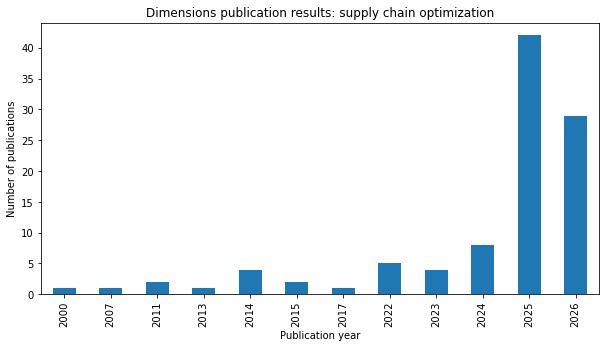

In [17]:
publications_by_year.plot(
    kind="bar",
    xlabel="Publication year",
    ylabel="Number of publications",
    title=f"Dimensions publication results: {SEARCH_TERM}",
    figsize=(10, 5)
);


### A note about interpretation

This is an exploratory view of our returned records.

Before treating a query like this as a research landscape, we would need to think more carefully about:

- how the search term defines the research area
- which Dimensions fields are being searched
- result limits and pagination
- database coverage
- publication types
- organizations, researchers, and funders
- whether a structured field or category would define the topic better than a text search

Those are analytical choices, not merely programming choices.


## 8. Dimensions Contains More Than Publications

One reason Dimensions is especially interesting for research and patent informatics is that publications are only one part of the system.

Dimensions also contains other research-related data sources, including **grants and patents**.

For now, we will simply demonstrate that the same DSL can query another source.


In [19]:
grant_query = f'''
search grants
    for "{SEARCH_TERM}"
return grants[
    id
    + title
    + start_year
]
limit 10
'''

grant_result = dsl.query(grant_query)

grant_result.grants


Returned Grants: 10 (total = 3048)
Time: 0.69s


[{'id': 'grant.15463576',
  'start_year': 2027,
  'title': 'Lithiophilic Copper Coatings and Engineered Cell Conditions for High-Performance Anode-Free Lithium Metal Batteries'},
 {'id': 'grant.15551313',
  'start_year': 2027,
  'title': 'Collaborative Research: Make-it-Anywhere Distributed Additive Manufacturing: Enabling Part Quality Equivalence through Physics- and Data-Integrated Process Control'},
 {'id': 'grant.15551166',
  'start_year': 2027,
  'title': 'Collaborative Research: Make-it-Anywhere Distributed Additive Manufacturing: Enabling Part Quality Equivalence through Physics- and Data-Integrated Process Control'},
 {'id': 'grant.15645997',
  'start_year': 2026,
  'title': 'Crossing the Threshold to Fault-tolerant Digital Neutral Atom Quantum Computing'},
 {'id': 'grant.15551616',
  'start_year': 2026,
  'title': 'Extending Americas AI Training Data Leadership'},
 {'id': 'grant.15551414',
  'start_year': 2026,
  'title': 'AI Institute for Advances in Optimization'},
 {'id': '

We are not going to analyze the grant results yet.

The important point is that Dimensions lets us ask related questions across different kinds of research and innovation information.

A later workbook can build on this by examining relationships among:

**research → grants → publications → patents**


## 9. Try Your Own Research Topic

Change `SEARCH_TERM` and rerun the topic-search sections.

For example:

```python
SEARCH_TERM = "CAR T cell therapy"
```

or:

```python
SEARCH_TERM = "medical image segmentation"
```

Better yet, choose a topic from your own research, professional work, or area of interest.

Consider:

1. Do the publication results appear relevant?
2. What years and publication types are represented?
3. Which returned publications have been cited most often?
4. Does the same topic retrieve interesting grant records?
5. What additional Dimensions fields would you want to investigate?
6. How might grants, publications, or patents help you understand this research area differently?


## 10. What We Did

In this workbook, we followed a simple Dimensions workflow:

**DSL query → returned records → inspect data**

and then:

**research topic → publication search → pandas DataFrame → visualization**

Finally, we used the same topic to make a small query against the grants data source.

The goal was not to build a complete research landscape. It was to learn enough of the Dimensions query workflow to begin exploring topics independently.

A later Dimensions workbook can build on this foundation to investigate the more distinctive relationships among funding, research outputs, and patented inventions.
